In [1]:
#Importing Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ast 

In [2]:
#Loading Data
raw_data = pd.read_csv(r'C:\Users\MAJEED\Desktop\APPS\data_jobs.csv')
df = raw_data.copy()

In [3]:
#Data Cleanup
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])

In [4]:
df.dropna(subset = ['job_skills'], inplace = True)

In [5]:
def clean_list(skill_clean):
    return ast.literal_eval(skill_clean)

In [6]:
df['job_skills'] = df['job_skills'].apply(clean_list)

In [7]:
df_US = df[df['job_country'] == 'United States']

In [8]:
df_explode = df_US.explode('job_skills')
df_explode.head()

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills
3,Data Engineer,LEAD ENGINEER - PRINCIPAL ANALYST - PRINCIPAL ...,"San Antonio, TX",via Diversity.com,Full-time,False,"Texas, United States",2023-07-04 13:01:41,True,False,United States,NaN,NaN,NaN,Southwest Research Institute,python,"{'cloud': ['aws'], 'libraries': ['tensorflow',..."
3,Data Engineer,LEAD ENGINEER - PRINCIPAL ANALYST - PRINCIPAL ...,"San Antonio, TX",via Diversity.com,Full-time,False,"Texas, United States",2023-07-04 13:01:41,True,False,United States,NaN,NaN,NaN,Southwest Research Institute,c++,"{'cloud': ['aws'], 'libraries': ['tensorflow',..."
3,Data Engineer,LEAD ENGINEER - PRINCIPAL ANALYST - PRINCIPAL ...,"San Antonio, TX",via Diversity.com,Full-time,False,"Texas, United States",2023-07-04 13:01:41,True,False,United States,NaN,NaN,NaN,Southwest Research Institute,java,"{'cloud': ['aws'], 'libraries': ['tensorflow',..."
3,Data Engineer,LEAD ENGINEER - PRINCIPAL ANALYST - PRINCIPAL ...,"San Antonio, TX",via Diversity.com,Full-time,False,"Texas, United States",2023-07-04 13:01:41,True,False,United States,NaN,NaN,NaN,Southwest Research Institute,matlab,"{'cloud': ['aws'], 'libraries': ['tensorflow',..."
3,Data Engineer,LEAD ENGINEER - PRINCIPAL ANALYST - PRINCIPAL ...,"San Antonio, TX",via Diversity.com,Full-time,False,"Texas, United States",2023-07-04 13:01:41,True,False,United States,NaN,NaN,NaN,Southwest Research Institute,aws,"{'cloud': ['aws'], 'libraries': ['tensorflow',..."


In [9]:
df_job_title_count = df_US['job_title_short'].value_counts().reset_index(name = 'jobs_total')
df_job_title_count 

,job_title_short,jobs_total
0,Data Analyst,57391
1,Data Scientist,51621
2,Data Engineer,33306
3,Senior Data Scientist,11622
4,Senior Data Analyst,10428
5,Senior Data Engineer,8951
6,Business Analyst,6178
7,Software Engineer,1525
8,Machine Learning Engineer,818
9,Cloud Engineer,327


In [10]:
skills_count = df_explode.groupby(['job_title_short', 'job_skills']).size()
df_skills_count = skills_count.reset_index(name = 'skill_count')
df_skills_count = df_skills_count.sort_values(by = 'skill_count', ascending = False) 
df_skills_count

,job_title_short,job_skills,skill_count
886,Data Scientist,python,42379
472,Data Analyst,sql,34452
921,Data Scientist,sql,30034
351,Data Analyst,excel,27519
890,Data Scientist,r,26022
...,...,...,...
1313,Senior Data Engineer,asp.net core,1
228,Cloud Engineer,ms access,1
1020,Machine Learning Engineer,graphql,1
1582,Senior Data Scientist,mariadb,1


In [11]:
df_skills_percent = pd.merge(df_skills_count, df_job_title_count, how = 'left', on = 'job_title_short')
df_skills_percent['skill_percent'] = (df_skills_percent['skill_count'] / df_skills_percent['jobs_total']) * 100
df_skills_percent

,job_title_short,job_skills,skill_count,jobs_total,skill_percent
0,Data Scientist,python,42379,51621,82.096434
1,Data Analyst,sql,34452,57391,60.030318
2,Data Scientist,sql,30034,51621,58.181748
3,Data Analyst,excel,27519,57391,47.950027
4,Data Scientist,r,26022,51621,50.409717
...,...,...,...,...,...
1865,Senior Data Engineer,asp.net core,1,8951,0.011172
1866,Cloud Engineer,ms access,1,327,0.305810
1867,Machine Learning Engineer,graphql,1,818,0.122249
1868,Senior Data Scientist,mariadb,1,11622,0.008604


In [12]:
job_titles = df_skills_percent['job_title_short'].unique().tolist()
job_titles = sorted(job_titles[:3])
job_titles

['Data Analyst', 'Data Engineer', 'Data Scientist']

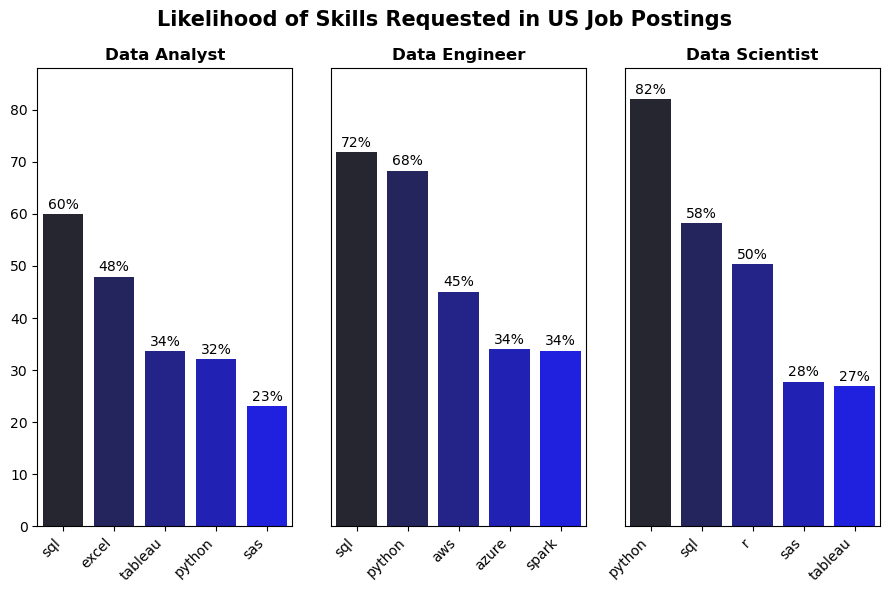

In [13]:
fig, ax = plt.subplots(1, len(job_titles), figsize=(9, 6))

for i, job_title in enumerate(job_titles):
    df_plot = df_skills_percent[df_skills_percent['job_title_short'] == job_title].head(5)
    sns.barplot(data=df_plot, x='job_skills', y='skill_percent', ax=ax[i], palette='dark:b')
    ax[i].set_xlabel('')
    ax[i].set_ylabel('')
    ax[i].set_ylim(0, 88)
    ax[i].set_xticklabels(ax[i].get_xticklabels(), rotation=45, ha='right')
    ax[i].set_title(job_title, fontsize=12, fontweight='bold')
    
    for n, v in enumerate(df_plot['skill_percent']):
        ax[i].text(n, v + 1, f'{v:.0f}%', ha = 'center')
    
    if i != len(job_titles) - 3:
            ax[i].set_yticks([])


fig.suptitle('Likelihood of Skills Requested in US Job Postings', fontsize=15, fontweight='bold')
fig.tight_layout(h_pad = 0.5)
plt.show()